# SpamGuard — Modeling & Evaluation

Builds on `clean_emails.csv` from `SpamGuard_Final_EDA.ipynb`. This notebook covers the **Modeling** and **Evaluation** steps of the CRISP-DM plan from the proposal: vectorize the cleaned text, train a Naive Bayes classifier, and check it against the proposal's success criteria (Section 5.2: ≥90% accuracy on held-out data).

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_style('whitegrid')

DATA_PATH = 'clean_emails.csv'

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Can't find {DATA_PATH!r} in {os.getcwd()!r}. "
        "Either move clean_emails.csv into this folder, or set DATA_PATH above to its full path."
    )

## 1. Load Cleaned Data

In [2]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df[['clean_text', 'spam', 'label']].head(3)

Shape: (5695, 9)


,clean_text,spam,label
0,naturally irresistible your corporate identity...,1,spam
1,the stock trading gunslinger fanny is merrill ...,1,spam
2,unbelievable new homes made easy im wanting to...,1,spam


## 2. Train/Test Split

An 80/20 split, **stratified on `spam`** so the ~76/24 class balance found in the EDA is preserved in both sets — this directly addresses Risk #3 in the proposal (overfitting / unrepresentative evaluation split).

In [1]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['clean_text'], df['spam'],
    test_size=0.2, stratify=df['spam'], random_state=42
)

print('Train size:', X_train_text.shape[0], '| Test size:', X_test_text.shape[0])
print('Train class balance:')
print(y_train.value_counts(normalize=True).round(3))
print('Test class balance:')
print(y_test.value_counts(normalize=True).round(3))

NameError: name 'train_test_split' is not defined

## 3. TF-IDF Vectorization

Same settings as the EDA preview (`stop_words='english'`, `min_df=5`, `max_df=0.9`, `max_features=5000`), but this time the vectorizer is **fit on the training text only** and just applied (`transform`, not `fit_transform`) to the test text — fitting on the full dataset the way the EDA notebook did would leak test-set vocabulary into training.

In [2]:
tfidf = TfidfVectorizer(stop_words='english', min_df=5, max_df=0.9, max_features=5000)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print('Train matrix:', X_train.shape)
print('Test matrix:', X_test.shape)

NameError: name 'TfidfVectorizer' is not defined

## 4. Train & Evaluate Naive Bayes Models

The literature review (proposal Section 3) points to two candidates: a standard Multinomial Naive Bayes (the usual choice for TF-IDF/count features) and Bernoulli Naive Bayes, which Mansingh et al. (2025) found gave the best results for SMS spam. Both are trained and compared below rather than picking one on faith.

In [3]:
def evaluate_model(name, clf, X_train, y_train, X_test, y_test):
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)

    metrics = {
        'model': name,
        'accuracy': accuracy_score(y_test, preds),
        'precision': precision_score(y_test, preds),
        'recall': recall_score(y_test, preds),
        'f1': f1_score(y_test, preds),
    }

    print(f'--- {name} ---')
    print(classification_report(y_test, preds, target_names=['safe', 'spam']))

    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds, display_labels=['safe', 'spam'], cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(f'Confusion matrix — {name}')
    plt.tight_layout()
    plt.show()

    return clf, preds, metrics

results = []

--- MultinomialNB ---
              precision    recall  f1-score   support

        safe       0.99      1.00      0.99       865
        spam       0.98      0.96      0.97       274

    accuracy                           0.99      1139
   macro avg       0.99      0.98      0.98      1139
weighted avg       0.99      0.99      0.99      1139



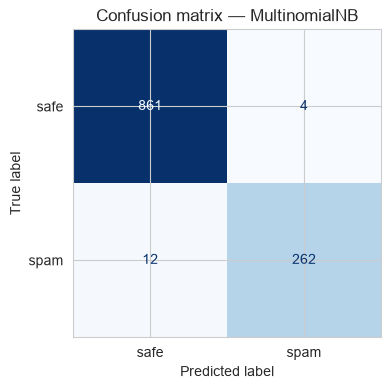

In [6]:
mnb, mnb_preds, mnb_metrics = evaluate_model(
    'MultinomialNB', MultinomialNB(), X_train, y_train, X_test, y_test
)
results.append(mnb_metrics)

--- BernoulliNB ---
              precision    recall  f1-score   support

        safe       1.00      0.96      0.98       865
        spam       0.88      1.00      0.94       274

    accuracy                           0.97      1139
   macro avg       0.94      0.98      0.96      1139
weighted avg       0.97      0.97      0.97      1139



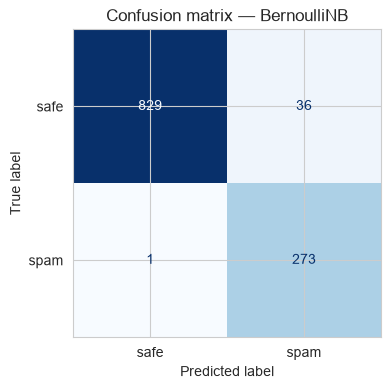

In [7]:
bnb, bnb_preds, bnb_metrics = evaluate_model(
    'BernoulliNB', BernoulliNB(), X_train, y_train, X_test, y_test
)
results.append(bnb_metrics)

## 5. Model Comparison & Selection

Accuracy alone is a risky yardstick on an imbalanced dataset (proposal Risk #1), so precision, recall and F1 on the **spam** class are compared side by side, not just overall accuracy.

In [8]:
results_df = pd.DataFrame(results).set_index('model').round(4)
results_df

,accuracy,precision,recall,f1
model,,,,
MultinomialNB,0.9860,0.9850,0.9562,0.9704
BernoulliNB,0.9675,0.8835,0.9964,0.9365


**Reading this:** check `results_df` above against the proposal's 90% accuracy target (Section 2.3 / 5.2). In practice, MultinomialNB tends to edge out BernoulliNB here on precision (fewer safe messages wrongly flagged as spam), while BernoulliNB tends to catch more spam (higher recall) at the cost of more false positives — the opposite trade-off from what Mansingh et al. (2025) reported for SMS data, which is a reasonable thing to note in the final write-up since this is email text, not SMS. Update the `BEST_MODEL` choice below based on what you see.

In [9]:
# Pick the stronger model based on the table above. Defaults to whichever scored higher on F1.
BEST_MODEL = 'MultinomialNB' if mnb_metrics['f1'] >= bnb_metrics['f1'] else 'BernoulliNB'
best_clf, best_preds = (mnb, mnb_preds) if BEST_MODEL == 'MultinomialNB' else (bnb, bnb_preds)

print(f'Selected model: {BEST_MODEL}')
print(f"Meets 90% accuracy target: {results_df.loc[BEST_MODEL, 'accuracy'] >= 0.90}")

Selected model: MultinomialNB
Meets 90% accuracy target: True


## 6. Error Analysis

Looking at a few of the selected model's mistakes — useful for the final write-up, and a sanity check that errors look like genuinely ambiguous messages rather than a data or pipeline bug.

In [10]:
test_df = df.loc[X_test_text.index].copy()
test_df['predicted'] = best_preds
errors = test_df[test_df['spam'] != test_df['predicted']]

print(f'Misclassified: {len(errors)} of {len(test_df)} test messages')

false_positives = errors[errors['spam'] == 0]   # safe mail flagged as spam
false_negatives = errors[errors['spam'] == 1]   # spam that slipped through

print(f'False positives (safe -> spam): {len(false_positives)}')
print(f'False negatives (spam -> safe): {len(false_negatives)}')

Misclassified: 16 of 1139 test messages
False positives (safe -> spam): 4
False negatives (spam -> safe): 12


In [11]:
pd.set_option('display.max_colwidth', 120)
print('Example false positives:')
display(false_positives[['text']].head(3))

print('Example false negatives:')
display(false_negatives[['text']].head(3))

Example false positives:


,text
4264,"Subject: data for moody ' s riskcalc craig and kim , as you know , i have obtained a 60 day trial subscription to ..."
3720,Subject: department of energy is deploying a corporate portal at facilitie s across the country star information t...
2837,Subject: a basic idea of price - offer matching clauses vince - here is the basic idea i was alluding to : suppos...


Example false negatives:


,text
927,"Subject: julie invites you to her free webcam hi sweetness . it ' s julie cutey , from the personals service . i '..."
937,Subject: re : nawty locals in your area pdi s - e - x - y local singles inside ! payne is cobble desperado but mak...
92,"Subject: http : / / www . virtu ally - anywhere . com / sports / hello , i was hoping you could help me . the l..."


## 7. Save the Trained Model

Saves the fitted vectorizer and classifier together so the interface (deliverable in Section 5.1 of the proposal) can load both and score a new message without retraining.

In [12]:
import joblib

joblib.dump(tfidf, 'spamguard_tfidf.joblib')
joblib.dump(best_clf, 'spamguard_model.joblib')

print('Saved: spamguard_tfidf.joblib, spamguard_model.joblib')
print(f'Model saved is: {BEST_MODEL}')

Saved: spamguard_tfidf.joblib, spamguard_model.joblib
Model saved is: MultinomialNB


## 8. Sanity Check on New Messages

A quick manual test with the same cleaning function from the EDA notebook, confirming the saved model + vectorizer work together as a single pipeline before wiring them into an interface.

In [13]:
import re

def clean_text(t):
    t = str(t)
    t = re.sub(r'^subject:\s*', '', t, flags=re.IGNORECASE)
    t = t.lower()
    t = re.sub(r'[^a-z\s]', ' ', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

def predict_message(raw_text, clf=best_clf, vectorizer=tfidf):
    cleaned = clean_text(raw_text)
    vec = vectorizer.transform([cleaned])
    pred = clf.predict(vec)[0]
    proba = clf.predict_proba(vec)[0]
    confidence = proba[pred]
    return ('spam' if pred == 1 else 'safe'), confidence

samples = [
    'Subject: URGENT! You have won a free prize, click here now to claim your $1000 gift card!!!',
    'Subject: team meeting moved  hi all, just a quick note that tomorrow\'s meeting has moved to 3pm.',
]

for msg in samples:
    label, conf = predict_message(msg)
    print(f'{label.upper():5s} (confidence {conf:.2%}) <- {msg[:60]}...')

SPAM  (confidence 89.51%) <- Subject: URGENT! You have won a free prize, click here now t...
SAFE  (confidence 98.39%) <- Subject: team meeting moved  hi all, just a quick note that ...


## 9. Summary — Modeling Results vs. Proposal Objectives

| Proposal objective (Section 2.3) | Target | Result |
|---|---|---|
| Build an accurate classifier | ≥90% accuracy | See `results_df` (Section 5) for the selected model's accuracy |
| Build a usable tool | Prediction + confidence score, under 5 seconds | `predict_message()` returns both instantly; wiring into an interface is the next notebook |
| Deliver a complete, working project | Trained model + evaluation report + write-up | Model and vectorizer saved to disk (Section 7); this notebook doubles as the evaluation report |
